<a href="https://colab.research.google.com/github/sushant1811/Sushant-kumar/blob/main/EDA_phase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [2]:
#Loading the Dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/school93_98.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")
print("Rows and Columns:", df.shape)

df.head()

Dataset Loaded Successfully
Rows and Columns: (10668, 19)


,rownames,distid,schid,lunch,enrol,exppp,math4,year,y93,y94,y95,y96,y97,y98,rexpp,found,lenrol,lrexpp,lavgrexpp
0,1,34010,1,39.799999,256.0,2506.0,46.599998,1993,1,0,0,0,0,0,2783.480957,NaN,5.545177,7.931458,NaN
1,2,34010,1,35.000000,248.0,2870.0,44.700001,1994,0,1,0,0,0,0,3108.198486,NaN,5.513429,8.041799,7.988149
2,3,34010,1,36.590000,244.0,4176.0,86.500000,1995,0,0,1,0,0,0,4397.953125,4478.0,5.497168,8.388894,8.230331
3,4,34010,1,40.549999,247.0,4333.0,84.300003,1996,0,0,0,1,0,0,4432.418945,4754.0,5.509388,8.396701,8.392805
4,5,34010,1,49.490002,291.0,3666.0,83.800003,1997,0,0,0,0,1,0,3666.000000,5032.0,5.673323,8.206857,8.306277


In [3]:
#Basic Statistical Analysis
print("Shape of Dataset:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nStatistical Summary Including Categorical Columns:")
print(df.describe(include="all"))

Shape of Dataset:
(10668, 19)

Column Names:
Index(['rownames', 'distid', 'schid', 'lunch', 'enrol', 'exppp', 'math4',
       'year', 'y93', 'y94', 'y95', 'y96', 'y97', 'y98', 'rexpp', 'found',
       'lenrol', 'lrexpp', 'lavgrexpp'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10668 entries, 0 to 10667
Data columns (total 19 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   rownames   10668 non-null  int64  
 1   distid     10668 non-null  int64  
 2   schid      10668 non-null  int64  
 3   lunch      10365 non-null  float64
 4   enrol      10499 non-null  float64
 5   exppp      9731 non-null   float64
 6   math4      10565 non-null  float64
 7   year       10668 non-null  int64  
 8   y93        10668 non-null  int64  
 9   y94        10668 non-null  int64  
 10  y95        10668 non-null  int64  
 11  y96        10668 non-null  int64  
 12  y97        10668 non-null  int64  
 13  y98    

In [4]:
#Handling Missing Data
print("Missing Values Before Handling")

print(df.isnull().sum())

# Filling numerical columns with mean

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

# Filling categorical columns with mode

categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Handling")

print(df.isnull().sum())

Missing Values Before Handling
rownames        0
distid          0
schid           0
lunch         303
enrol         169
exppp         937
math4         103
year            0
y93             0
y94             0
y95             0
y96             0
y97             0
y98             0
rexpp         937
found        3556
lenrol        169
lrexpp        937
lavgrexpp    3151
dtype: int64

Missing Values After Handling
rownames     0
distid       0
schid        0
lunch        0
enrol        0
exppp        0
math4        0
year         0
y93          0
y94          0
y95          0
y96          0
y97          0
y98          0
rexpp        0
found        0
lenrol       0
lrexpp       0
lavgrexpp    0
dtype: int64


In [5]:
#Data Cleaning
print("Duplicate Rows Before Cleaning:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.columns = df.columns.str.strip()

print("Duplicate Rows After Cleaning:", df.duplicated().sum())

print("\nCurrent Data Types")

print(df.dtypes)

Duplicate Rows Before Cleaning: 0
Duplicate Rows After Cleaning: 0

Current Data Types
rownames       int64
distid         int64
schid          int64
lunch        float64
enrol        float64
exppp        float64
math4        float64
year           int64
y93            int64
y94            int64
y95            int64
y96            int64
y97            int64
y98            int64
rexpp        float64
found        float64
lenrol       float64
lrexpp       float64
lavgrexpp    float64
dtype: object


In [6]:
#Data Transformation
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = scaler.fit_transform(df[numeric_columns])

print(df.head())

   rownames    distid  schid   lunch     enrol     exppp     math4  year  y93  \
0  0.000000  0.402145    0.0  0.3980  0.184993  0.168980  0.456212   0.0  1.0   
1  0.000094  0.402145    0.0  0.3500  0.179049  0.196293  0.436864   0.2  0.0   
2  0.000187  0.402145    0.0  0.3659  0.176077  0.294290  0.862525   0.4  0.0   
3  0.000281  0.402145    0.0  0.4055  0.178306  0.306070  0.840122   0.6  0.0   
4  0.000375  0.402145    0.0  0.4949  0.210996  0.256022  0.835031   0.8  0.0   

   y94  y95  y96  y97  y98     rexpp     found    lenrol    lrexpp  lavgrexpp  
0  0.0  0.0  0.0  0.0  0.0  0.173392  0.242666  0.683729  0.578963   0.430905  
1  1.0  0.0  0.0  0.0  0.0  0.195901  0.242666  0.677698  0.606870   0.292697  
2  0.0  1.0  0.0  0.0  0.0  0.285305  0.041394  0.674609  0.694658   0.414220  
3  0.0  0.0  1.0  0.0  0.0  0.287695  0.082490  0.676931  0.696633   0.495747  
4  0.0  0.0  0.0  1.0  0.0  0.234567  0.123883  0.708072  0.648617   0.452329  


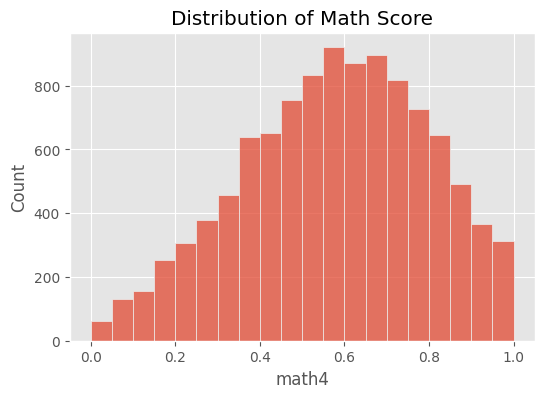

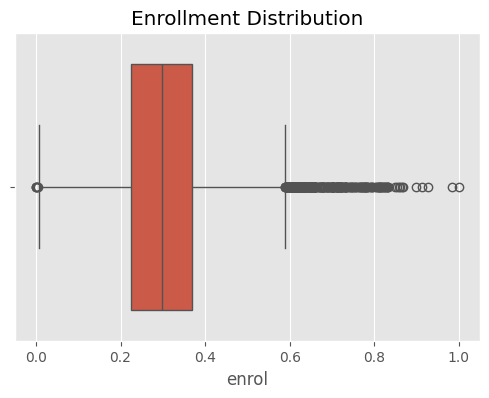

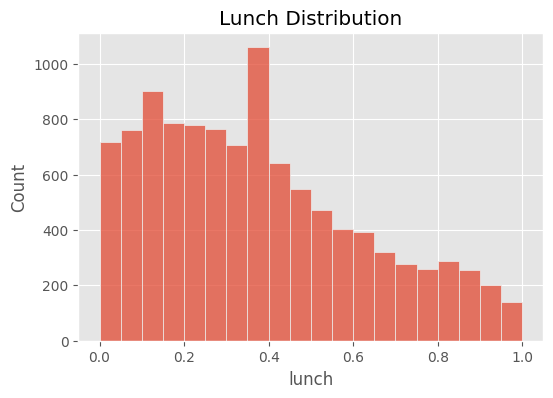

In [7]:
#Univariate Analysis
plt.figure(figsize=(6,4))
sns.histplot(df["math4"], bins=20)
plt.title("Distribution of Math Score")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x=df["enrol"])
plt.title("Enrollment Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df["lunch"], bins=20)
plt.title("Lunch Distribution")
plt.show()

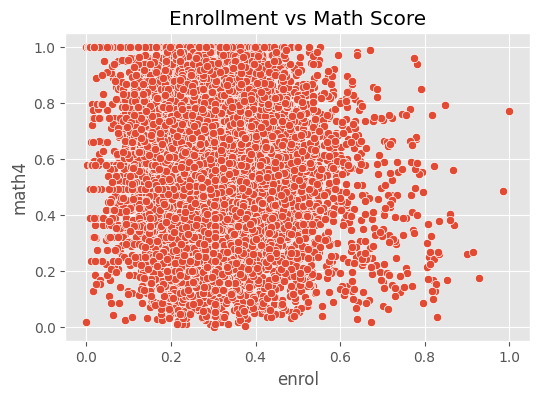

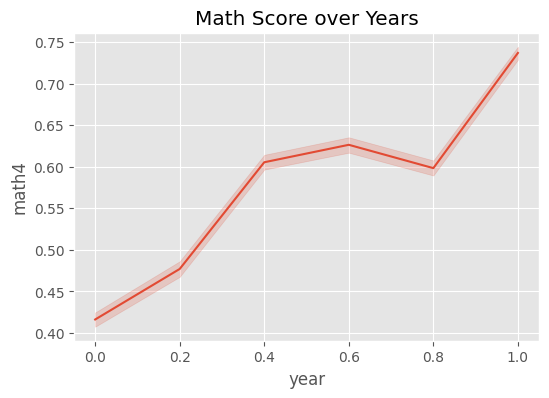

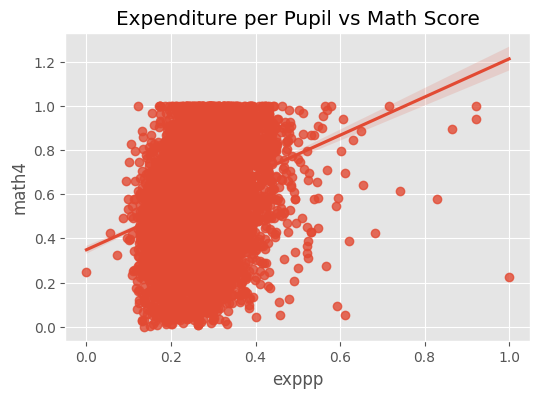

In [8]:
#Bivariate Analysis
plt.figure(figsize=(6,4))
sns.scatterplot(x="enrol", y="math4", data=df)
plt.title("Enrollment vs Math Score")
plt.show()

plt.figure(figsize=(6,4))
sns.lineplot(x="year", y="math4", data=df)
plt.title("Math Score over Years")
plt.show()

plt.figure(figsize=(6,4))
sns.regplot(x="exppp", y="math4", data=df)
plt.title("Expenditure per Pupil vs Math Score")
plt.show()

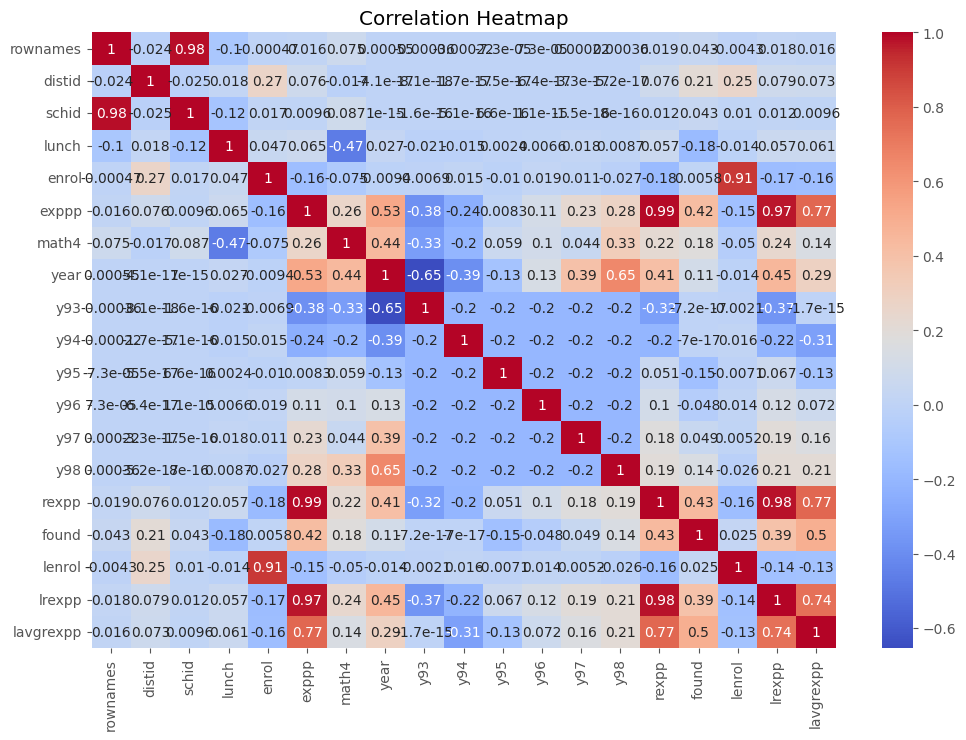

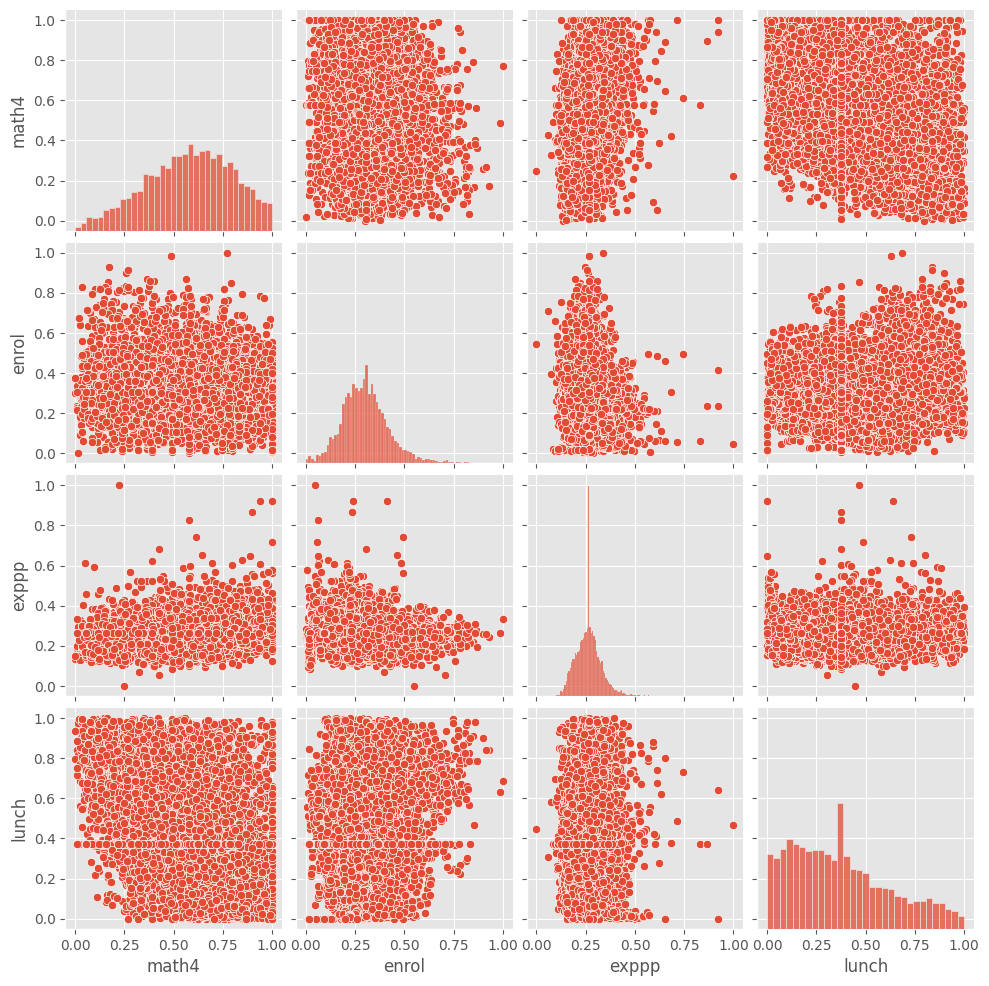

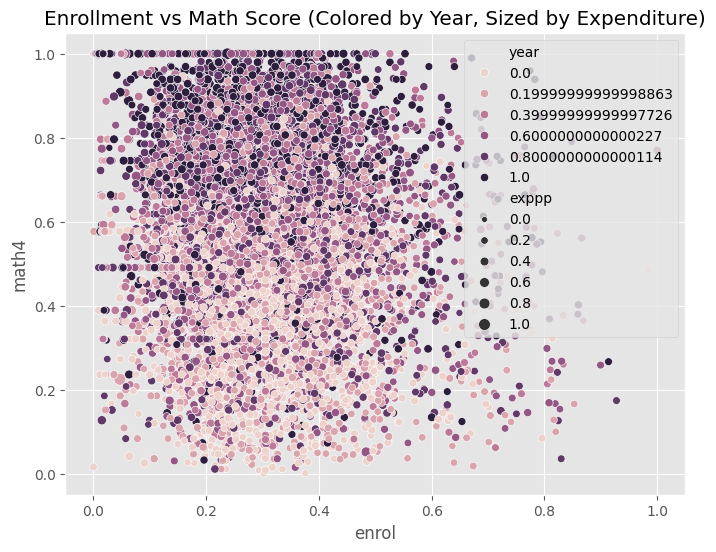

In [10]:
#Multivariate Analysis

plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


sns.pairplot(df[['math4', 'enrol', 'exppp', 'lunch']])
plt.show()


plt.figure(figsize=(8,6))
sns.scatterplot(x='enrol', y='math4', hue='year', size='exppp', data=df)
plt.title("Enrollment vs Math Score (Colored by Year, Sized by Expenditure)")
plt.show()